In [139]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM
from sklearn.preprocessing import MinMaxScaler

In [141]:
# 1. Veriyi oku
df = pd.read_csv("all_data_ratio.csv", encoding='utf-8-sig')

In [143]:
# 2. Sadece Adana'yı seç
df_adana = df[df['il_adı'] == 'Adana'].copy()

In [145]:
# 3. Gerekli değişkenleri seç
X = df_adana[['yıl', 'nufus']]
y = df_adana['uzman']

In [147]:
# 4. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X, y)

LinearRegression()

In [149]:
# 5. Random Forest
rf_model = RandomForestRegressor(random_state=42, n_estimators=100)
rf_model.fit(X, y)

RandomForestRegressor(random_state=42)

In [151]:
nufus_2023 = 2270298  # örnek veri
nufus_2024 = 2280484  # örnek veri

X_future = pd.DataFrame({
    'yıl': [2023, 2024],
    'nufus': [nufus_2023, nufus_2024]
})

In [153]:
# 7. Linear Regression ve Random Forest Tahminleri
lr_preds = lr_model.predict(X_future)
rf_preds = rf_model.predict(X_future)


--- Adana Uzman Doktor Tahminleri ---
2023:
  Linear Regression Tahmini: 3577
  Random Forest Tahmini: 3457
  LSTM Tahmini: 7
2024:
  Linear Regression Tahmini: 3700
  Random Forest Tahmini: 3457
  LSTM Tahmini: 7


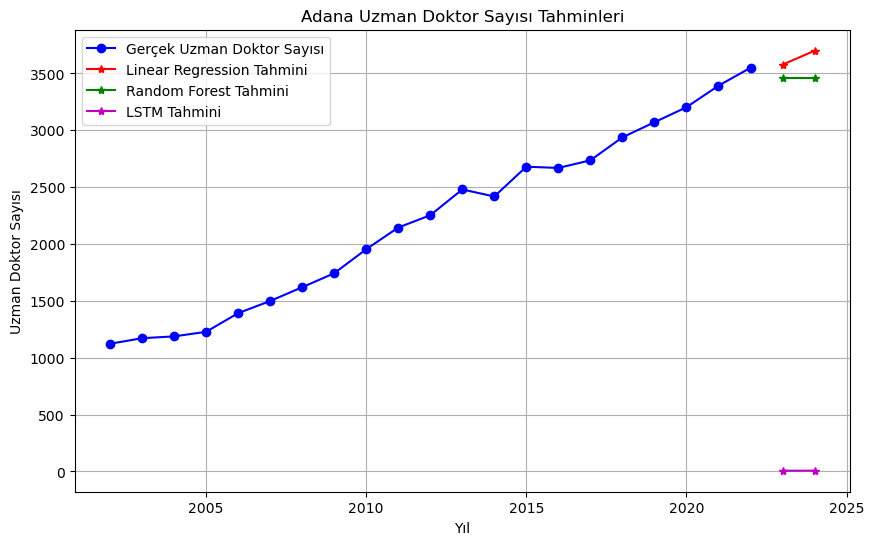

In [163]:
# 9. Sonuçları yazdır
print("\n--- Adana Uzman Doktor Tahminleri ---")
for i, year in enumerate([2023, 2024]):
    print(f"{year}:")
    print(f"  Linear Regression Tahmini: {lr_preds[i]:.0f}")
    print(f"  Random Forest Tahmini: {rf_preds[i]:.0f}")

# 10. (Opsiyonel) Grafikle karşılaştırma
plt.figure(figsize=(10,6))
plt.plot(df_adana['yıl'], y, 'bo-', label='Gerçek Uzman Doktor Sayısı')
plt.plot(X_future['yıl'], lr_preds, 'r*-', label='Linear Regression Tahmini')
plt.plot(X_future['yıl'], rf_preds, 'g*-', label='Random Forest Tahmini')
plt.xlabel('Yıl')
plt.ylabel('Uzman Doktor Sayısı')
plt.title('Adana Uzman Doktor Sayısı Tahminleri')
plt.legend()
plt.grid(True)
plt.show()